# Credit Scoring Capstone
## Notebook 01 — Data Preparation and Exploratory Data Analysis

This notebook explores and prepares the Home Credit Default Risk dataset
for the credit-scoring modelling pipeline.

### Objectives
- Inspect the dataset structure
- Examine class imbalance
- Investigate missing values
- Explore numerical and categorical variables
- Identify anomalies and structural missingness
- Perform initial feature engineering
- Save the cleaned dataset for modelling

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

In [4]:
data_path = "../data/application_train.csv"

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.022,0.0198,0.0,0.0,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.079,0.0554,0.0,0.0,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

## 1. Dataset Overview

This section examines the structure of the dataset, including its dimensions,
data types, identifiers, and duplicate observations.

In [7]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nData types:")
print(df.dtypes.value_counts())

print("\nMemory usage:")
print(f"{df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

Number of rows: 307511
Number of columns: 122

Data types:
float64    65
int64      41
str        16
Name: count, dtype: int64

Memory usage:
504.99 MB


In [9]:
print("Unique applicant IDs:", df["SK_ID_CURR"].nunique())
print("Duplicated applicant IDs:", df["SK_ID_CURR"].duplicated().sum())
print("Duplicated rows:", df.duplicated().sum())

Unique applicant IDs: 307511
Duplicated applicant IDs: 0
Duplicated rows: 0


## 2. Target Distribution

`TARGET` represents the credit outcome used for the classification task.

- `TARGET = 0`: Non-default
- `TARGET = 1`: Default

The class distribution is examined to determine whether the dataset is imbalanced.

In [12]:
target_counts = df["TARGET"].value_counts()
target_pct = df["TARGET"].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_pct
})

target_summary

,Count,Percentage
TARGET,,
0,282686,91.927118
1,24825,8.072882


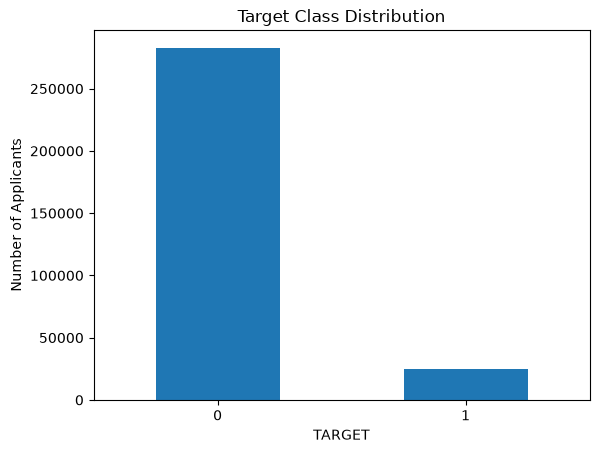

In [14]:
target_counts.plot(
    kind="bar",
    title="Target Class Distribution"
)

plt.xlabel("TARGET")
plt.ylabel("Number of Applicants")
plt.xticks(rotation=0)
plt.show()

### Interpretation

The dataset is strongly imbalanced. Approximately 91.9% of applicants belong
to the non-default class, while only about 8.1% belong to the default class.

This imbalance is important for later modelling. Accuracy alone would not be
an appropriate evaluation metric because a model predicting every applicant
as non-default would already achieve approximately 91.9% accuracy.

Therefore, later modelling stages will consider metrics such as ROC-AUC,
PR-AUC, F1 score, Brier score, and probability calibration.

## 3. Missing-Value Analysis

Missing values are examined to understand their extent across the dataset.

A high percentage of missing values does not automatically mean that a feature
should be removed. In some variables, missingness may represent structural or
meaningful information about an applicant.

In [18]:
missing_count = df.isnull().sum()
missing_pct = df.isnull().mean() * 100

missing_summary = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_pct
})

missing_summary = (
    missing_summary[
        missing_summary["Missing_Count"] > 0
    ]
    .sort_values(
        "Missing_Percentage",
        ascending=False
    )
)

print(
    "Columns with missing values:",
    len(missing_summary)
)

missing_summary.head(20)

Columns with missing values: 67


,Missing_Count,Missing_Percentage
COMMONAREA_MEDI,214865,69.872297
COMMONAREA_MODE,214865,69.872297
COMMONAREA_AVG,214865,69.872297
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
FONDKAPREMONT_MODE,210295,68.386172
LIVINGAPARTMENTS_AVG,210199,68.354953
LIVINGAPARTMENTS_MEDI,210199,68.354953
LIVINGAPARTMENTS_MODE,210199,68.354953


In [20]:
missing_groups = pd.DataFrame({
    "Missing Range": [
        "> 70%",
        "50% - 70%",
        "20% - 50%",
        "< 20%"
    ],
    "Number of Columns": [
        (missing_summary["Missing_Percentage"] > 70).sum(),

        (
            (missing_summary["Missing_Percentage"] >= 50) &
            (missing_summary["Missing_Percentage"] <= 70)
        ).sum(),

        (
            (missing_summary["Missing_Percentage"] >= 20) &
            (missing_summary["Missing_Percentage"] < 50)
        ).sum(),

        (
            missing_summary["Missing_Percentage"] < 20
        ).sum()
    ]
})

missing_groups

,Missing Range,Number of Columns
0,> 70%,0
1,50% - 70%,41
2,20% - 50%,9
3,< 20%,17


In [22]:
missing_summary.head(25)

,Missing_Count,Missing_Percentage
COMMONAREA_MEDI,214865,69.872297
COMMONAREA_MODE,214865,69.872297
COMMONAREA_AVG,214865,69.872297
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
FONDKAPREMONT_MODE,210295,68.386172
LIVINGAPARTMENTS_AVG,210199,68.354953
LIVINGAPARTMENTS_MEDI,210199,68.354953
LIVINGAPARTMENTS_MODE,210199,68.354953


### Interpretation

A total of 67 variables contain missing values. A substantial number of
features have more than 50% missing observations, particularly variables
related to property and building characteristics.

However, these variables are not automatically removed. Missingness may
contain information about the applicant or the availability/applicability of
particular information.

Therefore, the modelling pipeline will initially retain these variables and
handle missing values through model-specific preprocessing.

## 4. Structural Missingness

Some missing values may occur because a variable is not applicable to a
particular applicant rather than because information was accidentally omitted.

Two relationships are examined:

1. Car ownership and car age
2. Income type and occupation information

In [26]:
car_missing = pd.crosstab(
    df["FLAG_OWN_CAR"],
    df["OWN_CAR_AGE"].isna(),
    margins=True
)

car_missing.columns = [
    "Car_Age_Known",
    "Car_Age_Missing",
    "Total"
]

car_missing

,Car_Age_Known,Car_Age_Missing,Total
FLAG_OWN_CAR,,,
N,0,202924,202924
Y,104582,5,104587
All,104582,202929,307511


### Car Ownership Interpretation

Missing values in `OWN_CAR_AGE` are strongly related to car ownership.
Applicants who do not own a car naturally have no recorded car age.

Therefore, missing `OWN_CAR_AGE` should not automatically be interpreted as
poor data quality. The missingness contains structural information about the
applicant.

In [29]:
occupation_missing = pd.crosstab(
    df["NAME_INCOME_TYPE"],
    df["OCCUPATION_TYPE"].isna()
)

occupation_missing.columns = [
    "Occupation_Known",
    "Occupation_Missing"
]

occupation_missing["Total"] = (
    occupation_missing["Occupation_Known"]
    + occupation_missing["Occupation_Missing"]
)

occupation_missing.sort_values(
    "Occupation_Missing",
    ascending=False
)

,Occupation_Known,Occupation_Missing,Total
NAME_INCOME_TYPE,,,
Pensioner,5,55357,55362
Working,133854,24920,158774
Commercial associate,59320,12297,71617
State servant,17916,3787,21703
Unemployed,0,22,22
Student,13,5,18
Businessman,8,2,10
Maternity leave,4,1,5


### Occupation Interpretation

Missing `OCCUPATION_TYPE` values are not distributed randomly across income
groups. Pensioners and unemployed applicants have particularly high levels of
missing occupation information.

This suggests that some missing occupation values may represent
non-applicability or differences in how employment information is recorded.

For this reason, missing categorical values will later be represented
explicitly during preprocessing rather than being replaced with the most
common occupation.

## 5. Categorical Variable Exploration

Categorical variables are examined to understand their distributions,
cardinality, missing values, and unusual categories.

This analysis helps determine how categorical features should later be
encoded during model preprocessing.

In [33]:
categorical_cols_eda = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Number of categorical variables:", len(categorical_cols_eda))
print(categorical_cols_eda)

Number of categorical variables: 16
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


C:\Users\USER\AppData\Local\Temp\ipykernel_14444\659399033.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols_eda = df.select_dtypes(


In [35]:
categorical_summary = pd.DataFrame({
    "Unique_Categories": df[categorical_cols_eda].nunique(),
    "Missing_Count": df[categorical_cols_eda].isna().sum(),
    "Missing_Percentage": df[categorical_cols_eda].isna().mean() * 100
})

categorical_summary.sort_values(
    "Unique_Categories",
    ascending=False
)

,Unique_Categories,Missing_Count,Missing_Percentage
ORGANIZATION_TYPE,58,0,0.000000
OCCUPATION_TYPE,18,96391,31.345545
NAME_INCOME_TYPE,8,0,0.000000
NAME_TYPE_SUITE,7,1292,0.420148
WALLSMATERIAL_MODE,7,156341,50.840783
WEEKDAY_APPR_PROCESS_START,7,0,0.000000
NAME_FAMILY_STATUS,6,0,0.000000
NAME_HOUSING_TYPE,6,0,0.000000
NAME_EDUCATION_TYPE,5,0,0.000000
FONDKAPREMONT_MODE,4,210295,68.386172


In [37]:
important_categorical = [
    "NAME_CONTRACT_TYPE",
    "CODE_GENDER",
    "FLAG_OWN_CAR",
    "FLAG_OWN_REALTY",
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "NAME_FAMILY_STATUS",
    "NAME_HOUSING_TYPE",
    "OCCUPATION_TYPE",
    "ORGANIZATION_TYPE"
]

for col in important_categorical:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- NAME_CONTRACT_TYPE ---
NAME_CONTRACT_TYPE
Cash loans         278232
Revolving loans     29279
Name: count, dtype: int64

--- CODE_GENDER ---
CODE_GENDER
F      202448
M      105059
XNA         4
Name: count, dtype: int64

--- FLAG_OWN_CAR ---
FLAG_OWN_CAR
N    202924
Y    104587
Name: count, dtype: int64

--- FLAG_OWN_REALTY ---
FLAG_OWN_REALTY
Y    213312
N     94199
Name: count, dtype: int64

--- NAME_INCOME_TYPE ---
NAME_INCOME_TYPE
Working                 158774
Commercial associate     71617
Pensioner                55362
State servant            21703
Unemployed                  22
Student                     18
Businessman                 10
Maternity leave              5
Name: count, dtype: int64

--- NAME_EDUCATION_TYPE ---
NAME_EDUCATION_TYPE
Secondary / secondary special    218391
Higher education                  74863
Incomplete higher                 10277
Lower secondary                    3816
Academic degree                     164
Name: count, dtype: int64

--- N

### Interpretation

The categorical variables vary considerably in their number of categories and
amount of missing information.

Some variables contain special categories such as `XNA` or `Unknown`, while
others contain actual missing (`NaN`) values. These values should not
automatically be treated as equivalent because their meaning may differ
between variables.

`ORGANIZATION_TYPE` has relatively high cardinality, while variables such as
car ownership and property ownership are binary. `OCCUPATION_TYPE` also
contains substantial missing information, which was shown earlier to be
related to applicant income type.

Categorical preprocessing will therefore be performed later within each
modelling pipeline rather than permanently encoding these variables during
EDA.

## 6. Numerical Variables and Outlier Exploration

Numerical variables are examined to identify their ranges, distributions,
and potentially unusual observations.

Extreme observations are not automatically removed because they may represent
genuine applicants. Instead, suspicious values are investigated before any
cleaning decision is made.

In [41]:
numerical_cols_eda = df.select_dtypes(
    include="number"
).columns.tolist()

print("Number of numerical variables:", len(numerical_cols_eda))

Number of numerical variables: 106


In [43]:
key_numerical = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",
    "DAYS_REGISTRATION",
    "DAYS_ID_PUBLISH",
    "OWN_CAR_AGE",
    "CNT_CHILDREN",
    "CNT_FAM_MEMBERS",
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3"
]

df[key_numerical].describe().T

,count,mean,std,min,25%,50%,75%,max
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,2.565000e+04,112500.000000,147150.000000,202500.000000,1.170000e+08
AMT_CREDIT,307511.0,599025.999706,402490.776996,4.500000e+04,270000.000000,513531.000000,808650.000000,4.050000e+06
AMT_ANNUITY,307499.0,27108.573909,14493.737315,1.615500e+03,16524.000000,24903.000000,34596.000000,2.580255e+05
AMT_GOODS_PRICE,307233.0,538396.207429,369446.460540,4.050000e+04,238500.000000,450000.000000,679500.000000,4.050000e+06
DAYS_BIRTH,307511.0,-16036.995067,4363.988632,-2.522900e+04,-19682.000000,-15750.000000,-12413.000000,-7.489000e+03
DAYS_EMPLOYED,307511.0,63815.045904,141275.766519,-1.791200e+04,-2760.000000,-1213.000000,-289.000000,3.652430e+05
DAYS_REGISTRATION,307511.0,-4986.120328,3522.886321,-2.467200e+04,-7479.500000,-4504.000000,-2010.000000,0.000000e+00
DAYS_ID_PUBLISH,307511.0,-2994.202373,1509.450419,-7.197000e+03,-4299.000000,-3254.000000,-1720.000000,0.000000e+00
OWN_CAR_AGE,104582.0,12.061091,11.944812,0.000000e+00,5.000000,9.000000,15.000000,9.100000e+01
CNT_CHILDREN,307511.0,0.417052,0.722121,0.000000e+00,0.000000,0.000000,1.000000,1.900000e+01


In [45]:
outlier_cols = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "CNT_CHILDREN",
    "CNT_FAM_MEMBERS",
    "OWN_CAR_AGE"
]

quantiles = [0.01, 0.25, 0.50, 0.75, 0.95, 0.99, 0.999, 1.00]

df[outlier_cols].quantile(quantiles).T

,0.010,0.250,0.500,0.750,0.950,0.990,0.999,1.000
AMT_INCOME_TOTAL,45000.00,112500.0,147150.0,202500.0,337500.0,472500.0,900000.0,117000000.0
AMT_CREDIT,76410.00,270000.0,513531.0,808650.0,1350000.0,1854000.0,2517300.0,4050000.0
AMT_ANNUITY,6182.91,16524.0,24903.0,34596.0,53325.0,70006.5,110047.5,258025.5
AMT_GOODS_PRICE,67500.00,238500.0,450000.0,679500.0,1305000.0,1800000.0,2250000.0,4050000.0
CNT_CHILDREN,0.00,0.0,0.0,1.0,2.0,3.0,4.0,19.0
CNT_FAM_MEMBERS,1.00,2.0,2.0,3.0,4.0,5.0,6.0,20.0
OWN_CAR_AGE,0.00,5.0,9.0,15.0,30.0,64.0,65.0,91.0


### Outlier Interpretation

Several numerical variables contain extreme observations. For example,
`AMT_INCOME_TOTAL` has a maximum value substantially larger than its upper
quantiles. Other variables such as number of children, family size, and car
age also contain relatively unusual observations.

However, an unusual observation is not necessarily an invalid observation.
Automatically removing extreme applicants could eliminate genuine cases and
alter the population represented by the dataset.

Therefore, these observations are initially retained. Model-specific
preprocessing and robustness will be considered during the modelling stage.

### 6.1 DAYS_EMPLOYED Anomaly

The `DAYS_EMPLOYED` variable requires additional investigation because its
maximum value appears inconsistent with the interpretation of employment
duration.

In [49]:
print(df["DAYS_EMPLOYED"].describe())

print("\nMost frequent values:")
print(df["DAYS_EMPLOYED"].value_counts().head(10))

count    307511.000000
mean      63815.045904
std      141275.766519
min      -17912.000000
25%       -2760.000000
50%       -1213.000000
75%        -289.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64

Most frequent values:
DAYS_EMPLOYED
 365243    55374
-200         156
-224         152
-199         151
-230         151
-212         150
-229         143
-384         143
-231         140
-215         138
Name: count, dtype: int64


In [51]:
employment_anomaly = (df["DAYS_EMPLOYED"] == 365243).sum()

print("Number of 365243 values:", employment_anomaly)
print(
    "Percentage of dataset:",
    employment_anomaly / len(df) * 100
)

Number of 365243 values: 55374
Percentage of dataset: 18.00716071945394


In [53]:
print(
    "DAYS_EMPLOYED = 365243:",
    (df["DAYS_EMPLOYED"] == 365243).sum()
)

print(
    "ORGANIZATION_TYPE = XNA:",
    (df["ORGANIZATION_TYPE"] == "XNA").sum()
)

DAYS_EMPLOYED = 365243: 55374
ORGANIZATION_TYPE = XNA: 55374


### Interpretation

`DAYS_EMPLOYED = 365243` corresponds to approximately 1,000 years and
therefore cannot represent a genuine employment duration.

The value occurs for a substantial group of applicants and its frequency
matches the number of `XNA` observations in `ORGANIZATION_TYPE`. This suggests
that the value functions as a special or sentinel value rather than an actual
employment duration.

Instead of deleting these applicants, the value will be replaced with a
missing value and an additional indicator variable will preserve information
about whether the anomaly originally occurred.

## 7. Data Cleaning and Feature Engineering

Based on the exploratory analysis, a cleaned copy of the dataset is created.

The main transformations are:

- Preserve the original dataset in `df`
- Identify the `DAYS_EMPLOYED = 365243` sentinel value
- Create an indicator for this anomaly
- Replace the sentinel value with a missing value
- Convert age from days into years
- Convert employment duration from days into years

The original day-based variables are retained in `df_clean` for traceability,
but they will later be excluded from the model predictors to avoid duplicate
representations of the same information.

In [57]:
df_clean = df.copy()

print("Original shape:", df.shape)
print("Clean copy shape:", df_clean.shape)

Original shape: (307511, 122)
Clean copy shape: (307511, 122)


In [59]:
df_clean["DAYS_EMPLOYED_ANOM"] = (
    df_clean["DAYS_EMPLOYED"] == 365243
).astype(int)

df_clean["DAYS_EMPLOYED"] = (
    df_clean["DAYS_EMPLOYED"]
    .replace(365243, np.nan)
)

In [61]:
df_clean["AGE_YEARS"] = (
    -df_clean["DAYS_BIRTH"] / 365.25
)

df_clean["EMPLOYED_YEARS"] = (
    -df_clean["DAYS_EMPLOYED"] / 365.25
)

In [63]:
verification_cols = [
    "DAYS_EMPLOYED",
    "DAYS_EMPLOYED_ANOM",
    "AGE_YEARS",
    "EMPLOYED_YEARS"
]

df_clean[verification_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
DAYS_EMPLOYED,252137.0,-2384.169325,2338.360162,-17912.000000,-3175.000000,-1648.000000,-767.000000,0.000000
DAYS_EMPLOYED_ANOM,307511.0,0.180072,0.384248,0.000000,0.000000,0.000000,0.000000,1.000000
AGE_YEARS,307511.0,43.906900,11.947950,20.503765,33.984942,43.121150,53.886379,69.073238
EMPLOYED_YEARS,252137.0,6.527500,6.402081,-0.000000,2.099932,4.511978,8.692676,49.040383


In [65]:
print(
    "Original sentinel values:",
    (df["DAYS_EMPLOYED"] == 365243).sum()
)

print(
    "Remaining sentinel values:",
    (df_clean["DAYS_EMPLOYED"] == 365243).sum()
)

print(
    "Anomaly indicators:",
    df_clean["DAYS_EMPLOYED_ANOM"].sum()
)

print(
    "Missing DAYS_EMPLOYED after cleaning:",
    df_clean["DAYS_EMPLOYED"].isna().sum()
)

Original sentinel values: 55374
Remaining sentinel values: 0
Anomaly indicators: 55374
Missing DAYS_EMPLOYED after cleaning: 55374


In [67]:
print("Original dataset:", df.shape)
print("Clean dataset:", df_clean.shape)

Original dataset: (307511, 122)
Clean dataset: (307511, 125)


### Cleaning Summary

The cleaning process retains all applicants while correcting the invalid
employment-duration sentinel value.

Rather than deleting observations containing the sentinel, an anomaly indicator
is created to preserve potentially useful information. Age and employment
duration are also expressed in years to improve interpretability.

The cleaned dataset contains three additional engineered variables and will
serve as the input to the modelling stage. Model-specific imputation, encoding,
scaling, and feature selection are intentionally left for the modelling
pipeline.

## 8. Final Validation and Save Cleaned Dataset

Before saving the cleaned dataset, several checks are performed to confirm
that the cleaning and feature-engineering steps were completed correctly.

The resulting dataset will be used as the starting point for model development
in Notebook 02.

In [71]:
print("Final dataset shape:", df_clean.shape)

print("\nTarget distribution:")
print(df_clean["TARGET"].value_counts(normalize=True))

print("\nDuplicate rows:")
print(df_clean.duplicated().sum())

print("\nDuplicate applicant IDs:")
print(df_clean["SK_ID_CURR"].duplicated().sum())

print("\nEngineered features:")
print(
    df_clean[
        [
            "AGE_YEARS",
            "EMPLOYED_YEARS",
            "DAYS_EMPLOYED_ANOM"
        ]
    ].describe().T
)

Final dataset shape: (307511, 125)

Target distribution:
TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64

Duplicate rows:
0

Duplicate applicant IDs:
0

Engineered features:
                       count       mean        std        min        25%  \
AGE_YEARS           307511.0  43.906900  11.947950  20.503765  33.984942   
EMPLOYED_YEARS      252137.0   6.527500   6.402081  -0.000000   2.099932   
DAYS_EMPLOYED_ANOM  307511.0   0.180072   0.384248   0.000000   0.000000   

                          50%        75%        max  
AGE_YEARS           43.121150  53.886379  69.073238  
EMPLOYED_YEARS       4.511978   8.692676  49.040383  
DAYS_EMPLOYED_ANOM   0.000000   0.000000   1.000000  


In [73]:
print(
    "365243 values remaining:",
    (df_clean["DAYS_EMPLOYED"] == 365243).sum()
)

print(
    "Employment anomaly indicators:",
    df_clean["DAYS_EMPLOYED_ANOM"].sum()
)

print(
    "Missing employment values:",
    df_clean["DAYS_EMPLOYED"].isna().sum()
)

365243 values remaining: 0
Employment anomaly indicators: 55374
Missing employment values: 55374


In [75]:
output_path = "../data/application_clean.csv"

df_clean.to_csv(
    output_path,
    index=False
)

print("Cleaned dataset saved to:")
print(output_path)

Cleaned dataset saved to:
../data/application_clean.csv


In [77]:
df_check = pd.read_csv("../data/application_clean.csv")

print("Saved dataset shape:", df_check.shape)

Saved dataset shape: (307511, 125)


## Notebook 01 Summary

The Home Credit application dataset was explored and prepared for modelling.

Key findings include:

- The dataset contains 307,511 applicants and is strongly class-imbalanced,
  with approximately 8.1% belonging to the default class.
- Missing values occur in many variables, but some missingness is structural
  and may contain useful applicant information.
- Several numerical variables contain extreme observations, which were retained
  rather than automatically removed.
- `DAYS_EMPLOYED = 365243` was identified as an invalid sentinel value.
- The employment anomaly was preserved using an indicator variable.
- `AGE_YEARS` and `EMPLOYED_YEARS` were created for easier interpretation.
- The cleaned dataset contains 125 variables and was saved for use in the
  modelling stage.

The next notebook develops and evaluates the individual credit-scoring models.